# 04 · Matching Engine & Model Evaluation
The solution combines three approaches into a **hybrid**:

| Layer | What it does | Why |
|---|---|---|
| **A. NLP similarity** | TF-IDF and LSA cosine between profile text and JD text | Catches meaning beyond exact keywords |
| **B. Rule-based fit score** | Weighted mandatory/optional skills, experience, domain, role, flags, education | Transparent, matches how recruiters think, easy to audit |
| **C. ML classifier** | Predicts High / Medium / Low fit | Learns interactions and gives a probability for ranking |
| **Hybrid score** | 0.70 × rule + 0.30 × ML (NLP similarity enters through the ML features; weights chosen in section 7) | Final ranking used for shortlisting |

### Creating the target variable
There is no "hired" or "shortlisted" column, so the **High / Medium / Low** label is built from recruiter-style rules
(see `src/matching.py → assign_fit_label`):
- **High:** rule score ≥ 0.75 **and** ≥ 2/3 of must-have skills **and** experience in (or very near) the range
- **Low:** rule score < 0.50 **or** < 1/3 of must-have skills **or** an unrelated domain
- **Medium:** everything in between

In [1]:
# --- Setup -----------------------------------------------------------
# Add the project root folder to the Python path so "src" can be imported
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Standard libraries for data handling and charts
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # hide library warnings so the output stays readable
pd.set_option("display.max_columns", 60)   # show all columns when printing a dataframe
pd.set_option("display.max_colwidth", 80)  # do not cut long text too early

# Project settings: file paths, colours and the chart style
from src.config import *
from src.plot_style import set_style, save
set_style()

In [2]:
from src.matching import rule_score, assign_fit_label, RULE_WEIGHTS, hybrid_score, recommendation, explain
from src.features import to_list

# pair features from notebook 03 and the JDs
pairs = pd.read_csv(PAIR_FEATURES_FILE)
for c in ["mandatory_matched", "mandatory_missing", "optional_matched"]:
    pairs[c] = pairs[c].fillna("").apply(lambda s: [x for x in str(s).split("|") if x])
jds = pd.read_csv(JD_FILE).set_index("jd_id")
cands = pd.read_csv(CANDIDATE_FEATURES_FILE)
print(pairs.shape)

(50000, 32)


## 1. Rule-based fit score and fit labels

In [3]:
# Rule weights (they add up to 1.0)
pd.Series(RULE_WEIGHTS, name="weight").to_frame()

,weight
mandatory_match,0.30
experience_fit,0.15
domain_fit,0.10
role_fit,0.10
flag_fit,0.10
optional_match,0.10
education_fit,0.05
tool_match,0.05
resume_quality_score,0.05


In [4]:
pairs["rule_score"] = rule_score(pairs)
pairs["fit_label"] = assign_fit_label(pairs)

# overall label balance and per job
print(pairs["fit_label"].value_counts(normalize=True).round(3))
label_by_jd = pd.crosstab(pairs["jd_id"], pairs["fit_label"])[["High", "Medium", "Low"]]
label_by_jd.assign(job_title=jds["job_title"])

fit_label
Low       0.812
Medium    0.113
High      0.075
Name: proportion, dtype: float64


fit_label,High,Medium,Low,job_title
jd_id,,,,
JD01,687,1032,3281,Senior Cloud Backend Engineer
JD02,738,684,3578,DevOps Engineer
JD03,446,1715,2839,Junior Java Developer
JD04,530,99,4371,Data Scientist - NLP
JD05,243,1530,3227,Business Data Analyst
JD06,211,281,4508,HR Business Partner
JD07,277,224,4499,Talent Acquisition Specialist
JD08,346,51,4603,Corporate Compliance Counsel
JD09,189,0,4811,Mechanical Design Engineer


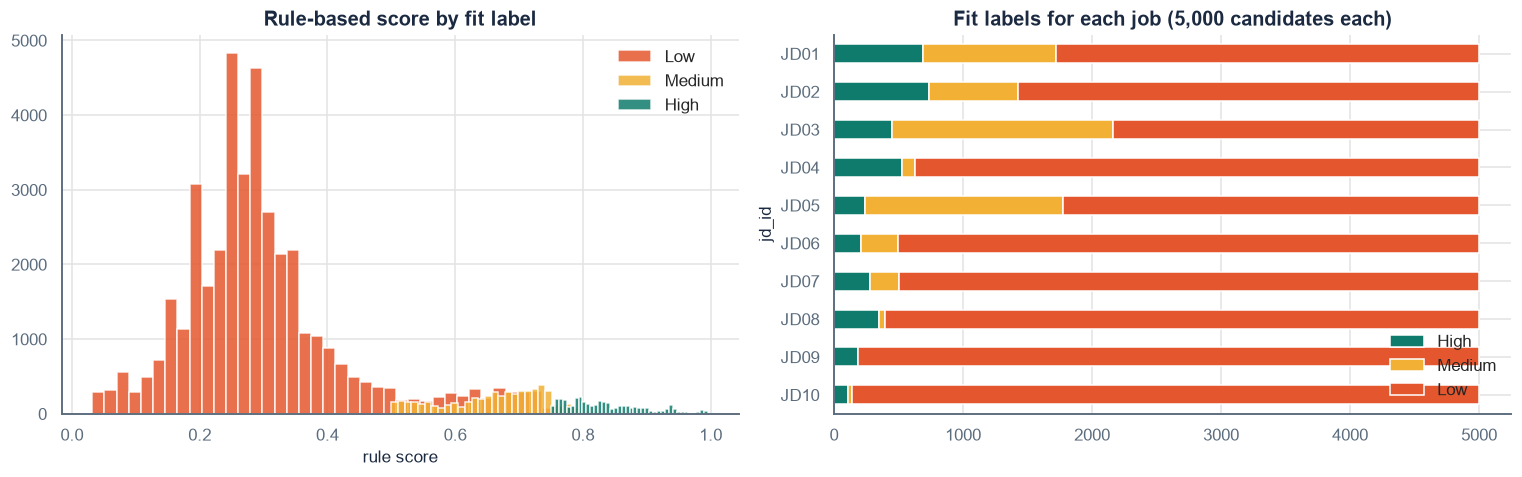

In [5]:
# Rule score distribution coloured by the label it produced
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lab in ["Low", "Medium", "High"]:
    axes[0].hist(pairs.loc[pairs["fit_label"] == lab, "rule_score"], bins=40, alpha=0.85,
                 color=FIT_COLORS[lab], label=lab)
axes[0].legend(frameon=False)
axes[0].set_title("Rule-based score by fit label")
axes[0].set_xlabel("rule score")

label_by_jd.plot.barh(stacked=True, ax=axes[1], color=[FIT_COLORS[c] for c in label_by_jd.columns])
axes[1].set_title("Fit labels for each job (5,000 candidates each)")
axes[1].invert_yaxis()
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "04_labels")
plt.show()

Most candidate–job pairs are **Low** — expected, because most of the 5,000 candidates belong to a different domain
than any single job. This is exactly the situation recruiters face: a large pile with a small number of good fits.
Because the classes are imbalanced, the models use **class weights** and are judged on **macro-F1** (treats all classes equally),
not plain accuracy.

## 2. Approach A — NLP similarity only (unsupervised baseline)
To judge the rankings fairly we need a yardstick that is **not** built from our own rule score.
An independent "relevant" definition is used: the candidate's **stated role is one of the JD's target roles** *and*
their experience is inside the JD range. This reflects what a hiring manager would call "on-profile".

In [6]:
# Independent relevance yardstick (not derived from the rule score)
role_ok = pairs.apply(lambda r: r["role_fit"] == 1.0, axis=1)
pairs["relevant_independent"] = (role_ok & (pairs["experience_fit"] == 1.0)).astype(int)

# Graded relevance from the fit label (High=2, Medium=1, Low=0)
pairs["label_gain"] = pairs["fit_label"].map({"High": 2, "Medium": 1, "Low": 0})


def ndcg_at_k(gains_sorted, all_gains, k):
    # Normalised Discounted Cumulative Gain: 1.0 = perfect ordering of the top k
    gains_sorted = np.asarray(gains_sorted)[:k]
    disc = 1 / np.log2(np.arange(2, len(gains_sorted) + 2))
    dcg = (gains_sorted * disc).sum()
    ideal = np.sort(np.asarray(all_gains))[::-1][:k]
    idcg = (ideal * disc[:len(ideal)]).sum()
    return dcg / idcg if idcg > 0 else 0.0


def ranking_metrics(df, score_col, k=20):
    # Average ranking quality over the 10 jobs for one scoring method
    rows = []
    for jd_id, g in df.groupby("jd_id"):
        g = g.sort_values(score_col, ascending=False)
        top = g.head(k)
        rows.append({
            "jd_id": jd_id,
            f"precision@{k} (independent)": top["relevant_independent"].mean(),
            f"precision@{k} (High label)": (top["fit_label"] == "High").mean(),
            f"ndcg@{k} (labels)": ndcg_at_k(top["label_gain"], g["label_gain"], k),
            f"ndcg@50 (independent)": ndcg_at_k(g["relevant_independent"].head(50), g["relevant_independent"], 50),
        })
    return pd.DataFrame(rows).set_index("jd_id")


# add a small random score as a "no model" baseline
rng = np.random.default_rng(RANDOM_STATE)
pairs["random_score"] = rng.random(len(pairs))

nlp_eval = pd.concat({m: ranking_metrics(pairs, m).mean() for m in ["random_score", "tfidf_sim", "lsa_sim"]}, axis=1).T
nlp_eval.round(3)

,precision@20 (independent),precision@20 (High label),ndcg@20 (labels),ndcg@50 (independent)
random_score,0.105,0.060,0.113,0.084
tfidf_sim,0.660,0.790,0.870,0.649
lsa_sim,0.635,0.795,0.893,0.615


NLP similarity alone is **far better than random** (precision@20 ≈ 0.65 vs 0.10). TF-IDF finds slightly more on-profile
candidates, while LSA orders the fit labels slightly better — they capture different things. But with templated resumes,
text alone cannot check experience range or must-have skills, so it misses about a third of the top-20 slots.

## 3. Approach C — Supervised classification (High / Medium / Low)
**Validation design:** `GroupKFold` with candidate id as the group. The same candidate appears once per job (10 rows),
so a normal random split would put the same person in train *and* test and inflate the scores.
Grouping keeps every candidate entirely in one fold.

Two feature sets are compared to show what feature engineering adds:
- **Raw profile features** — years, raw exposure flags, education rank, text similarity (no JD-specific engineering)
- **Engineered match features** — the candidate × job features built in notebook 03

In [7]:
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

# Raw profile features - one column from each identical pair (see notebook 01)
raw_flag_cols = ["management_experience_flag", "people_management_flag", "project_management_experience_flag",
                 "agile_scrum_experience_flag", "client_facing_experience_flag", "delivery_lead_experience_flag",
                 "cloud_experience_flag", "compliance_experience_flag", "enterprise_systems_experience_flag",
                 "offshore_onsite_model_experience_flag", "multi_vendor_coordination_flag",
                 "documentation_heavy_role_flag"]
pairs = pairs.merge(cands[["candidate_id"] + raw_flag_cols], on="candidate_id", how="left")
RAW_FEATURES = ["years_experience", "education_rank", "resume_quality_score", "tfidf_sim_scaled", "lsa_sim_scaled"] + raw_flag_cols

# Engineered match features
ENG_FEATURES = ["mandatory_match", "optional_match", "all_mandatory_flag", "tool_match", "experience_fit",
                "years_gap", "seniority_fit", "domain_fit", "role_fit", "flag_fit", "education_fit",
                "tfidf_sim_scaled", "lsa_sim_scaled", "resume_quality_score", "leadership_score",
                "delivery_score", "client_score", "governance_score", "years_experience"]

y = pairs["fit_label"]
groups = pairs["candidate_id"]
cv = GroupKFold(n_splits=5)

models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
}
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro", "weighted_f1": "f1_weighted",
           "roc_auc_ovr": "roc_auc_ovr", "recall_macro": "recall_macro"}

In [8]:
# Cross-validate every model on both feature sets (this cell takes ~1-2 minutes)
cv_rows = []
for feat_name, feats in [("Raw profile", RAW_FEATURES), ("Engineered match", ENG_FEATURES)]:
    for name, model in models.items():
        res = cross_validate(model, pairs[feats], y, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
        row = {"feature_set": feat_name, "model": name}
        for m in scoring:
            row[m] = res[f"test_{m}"].mean()
            row[m + "_std"] = res[f"test_{m}"].std()
        cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(OUTPUTS / "model_comparison.csv", index=False)
cv_results[["feature_set", "model", "accuracy", "macro_f1", "macro_f1_std", "weighted_f1", "roc_auc_ovr"]].round(3)

,feature_set,model,accuracy,macro_f1,macro_f1_std,weighted_f1,roc_auc_ovr
0,Raw profile,Dummy (most frequent),0.812,0.299,0.000,0.727,0.500
1,Raw profile,Logistic Regression,0.817,0.659,0.003,0.836,0.923
2,Raw profile,Random Forest,0.819,0.681,0.004,0.841,0.944
3,Raw profile,Gradient Boosting,0.844,0.710,0.008,0.860,0.954
4,Engineered match,Dummy (most frequent),0.812,0.299,0.000,0.727,0.500
5,Engineered match,Logistic Regression,0.984,0.962,0.003,0.985,0.999
6,Engineered match,Random Forest,0.989,0.971,0.004,0.989,1.000
7,Engineered match,Gradient Boosting,0.998,0.995,0.001,0.998,1.000


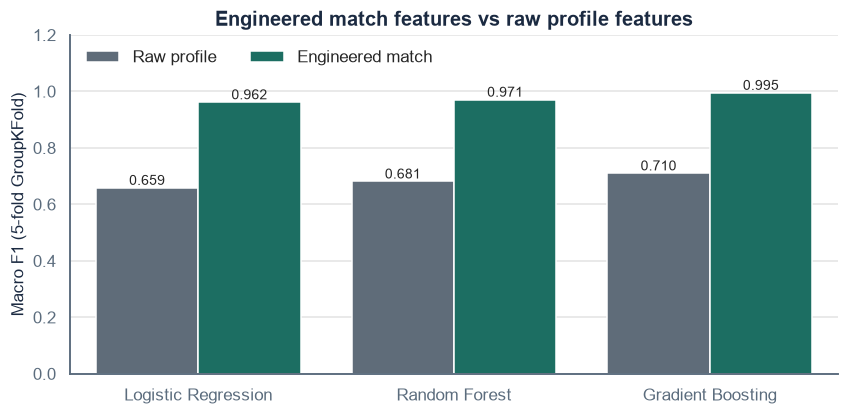

In [9]:
# Visual comparison of macro-F1
plot_df = cv_results[cv_results["model"] != "Dummy (most frequent)"]
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=plot_df, x="model", y="macro_f1", hue="feature_set", ax=ax,
            palette=[COLORS["slate"], COLORS["teal"]])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=9)
ax.set_ylim(0, 1.2)
ax.set_xlabel("")
ax.set_ylabel("Macro F1 (5-fold GroupKFold)")
ax.set_title("Engineered match features vs raw profile features")
ax.legend(frameon=False, title="", ncol=2, loc="upper left")
save(fig, "04_model_comparison")
plt.show()

**How to read this:**
- The *Dummy* model (always predicts "Low") shows that accuracy alone is misleading with imbalanced classes — look at macro-F1.
- On **raw profile features** models can only partly tell fits apart: they do not know which skills a specific job needs.
- With **engineered match features**, all models improve sharply → the feature engineering is what makes the matching work.
- ⚠️ **Honest caveat:** the label itself was created from these engineered features, so very high scores mean the model has
  *learned the recruiter rules well*, not that it predicts real hiring outcomes. Real shortlisting decisions should be
  collected to re-train and validate it (see recommendations).

## 4. Hold-out test of the best model

In [10]:
# Pick the best engineered-feature model by macro F1
best_name = (cv_results[cv_results["feature_set"] == "Engineered match"]
             .sort_values("macro_f1", ascending=False).iloc[0]["model"])
print("Best model:", best_name)

# 80/20 split by candidate for a final, untouched test set
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(pairs, y, groups))
X_train, X_test = pairs.iloc[train_idx][ENG_FEATURES], pairs.iloc[test_idx][ENG_FEATURES]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

from sklearn.base import clone
best_model = clone(models[best_name]).fit(X_train, y_train)
y_pred = best_model.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred, digits=3))

Best model: Gradient Boosting


              precision    recall  f1-score   support

        High      0.986     0.996     0.991       729
         Low      1.000     0.999     1.000      8158
      Medium      0.992     0.989     0.991      1113

    accuracy                          0.998     10000
   macro avg      0.993     0.995     0.994     10000
weighted avg      0.998     0.998     0.998     10000



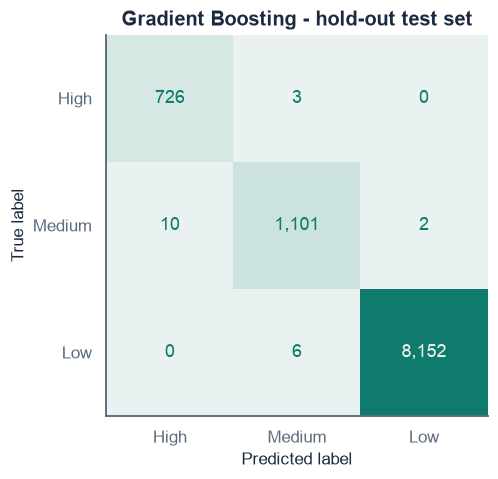

In [11]:
# Confusion matrix (rows = true label, columns = predicted)
labels = ["High", "Medium", "Low"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap=sns.light_palette(COLORS["teal"], as_cmap=True),
                                                       colorbar=False, values_format=",")
ax.set_title(f"{best_name} - hold-out test set")
ax.grid(False)
save(fig, "04_confusion_matrix")
plt.show()

## 5. What drives the fit prediction? (interpretability)

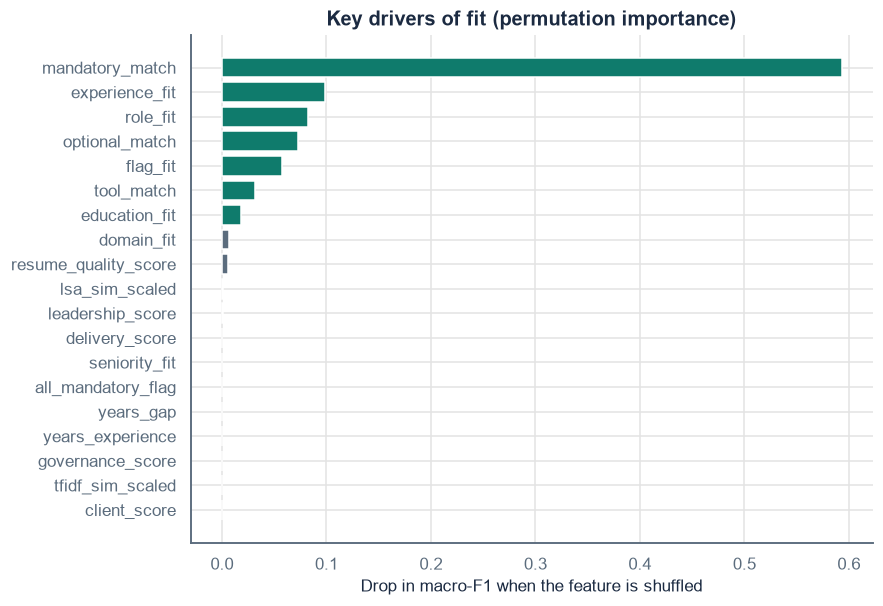

In [12]:
# Permutation importance: how much macro-F1 drops when one feature is shuffled
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=ENG_FEATURES).sort_values()
imp.to_csv(OUTPUTS / "feature_importance.csv", header=["importance"])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=[COLORS["teal"] if v > 0.01 else COLORS["slate"] for v in imp.values])
ax.set_title("Key drivers of fit (permutation importance)")
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled")
save(fig, "04_feature_importance")
plt.show()

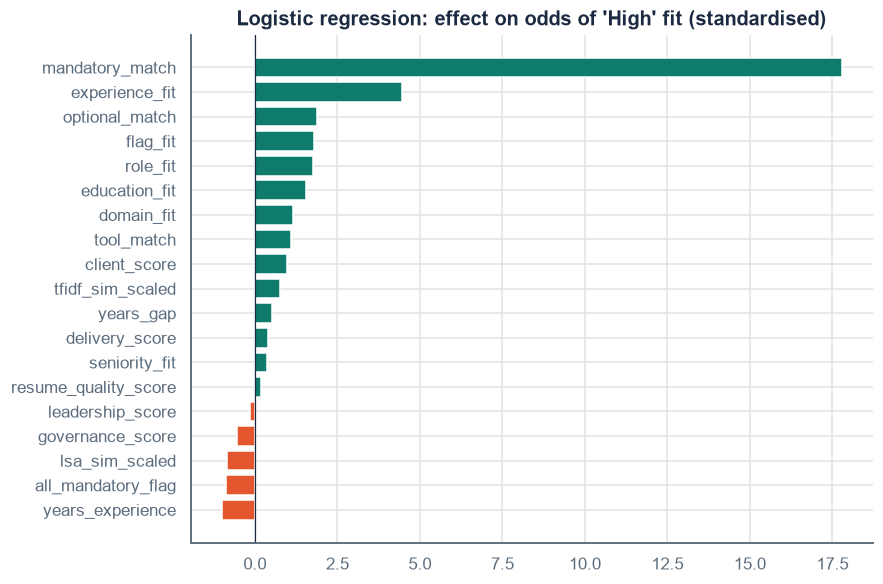

In [13]:
# Logistic regression coefficients for the 'High' class - shows direction (+ helps, - hurts)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
lr_model = lr[-1]
coef = pd.Series(lr_model.coef_[list(lr_model.classes_).index("High")], index=ENG_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coef.index, coef.values, color=[COLORS["teal"] if v > 0 else COLORS["coral"] for v in coef.values])
ax.axvline(0, color=COLORS["ink"], lw=0.8)
ax.set_title("Logistic regression: effect on odds of 'High' fit (standardised)")
save(fig, "04_lr_coefficients")
plt.show()

**Key drivers:** must-have skill coverage dominates by far, followed by experience-range fit, role alignment, optional
skills and the JD's required experience areas (flags). Domain fit adds little once role fit is known (the two overlap),
and text similarity adds almost nothing — consistent with the templated summaries found in notebook 01.
That ordering mirrors the rule weights, which is expected: the labels the model learns were built from those same rules.

## 6. Hybrid score and recommendation bands
ML probabilities are created **out-of-fold** (each candidate is scored by a model that never saw them) so the hybrid
score is not inflated. The ML part is turned into one number: `expected_fit = P(High) + 0.5 × P(Medium)`.

In [14]:
# Out-of-fold probabilities for every pair
oof_proba = cross_val_predict(clone(models[best_name]), pairs[ENG_FEATURES], y, groups=groups, cv=cv,
                              method="predict_proba", n_jobs=1)
classes = list(clone(models[best_name]).fit(X_train, y_train).classes_)
pairs["p_high"] = oof_proba[:, classes.index("High")]
pairs["p_medium"] = oof_proba[:, classes.index("Medium")]
pairs["ml_expected_fit"] = pairs["p_high"] + 0.5 * pairs["p_medium"]

pairs["hybrid_score"] = hybrid_score(pairs)
pairs["recommendation"] = pairs["hybrid_score"].apply(recommendation)
pd.crosstab(pairs["fit_label"], pairs["recommendation"])[["Shortlist", "Review", "Reject"]]

recommendation,Shortlist,Review,Reject
fit_label,,,
High,3763,9,0
Low,0,2,40576
Medium,177,4442,1031


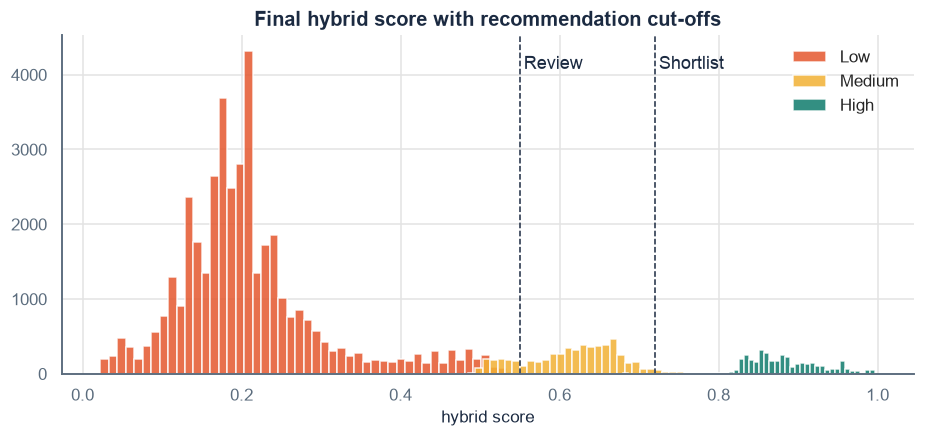

In [15]:
# Hybrid score distribution with the two cut-offs
fig, ax = plt.subplots(figsize=(10, 4))
for lab in ["Low", "Medium", "High"]:
    ax.hist(pairs.loc[pairs["fit_label"] == lab, "hybrid_score"], bins=50, alpha=0.85, color=FIT_COLORS[lab], label=lab)
for cut, txt in [(0.55, "Review"), (0.72, "Shortlist")]:
    ax.axvline(cut, color=COLORS["ink"], ls="--", lw=1)
    ax.text(cut + 0.005, ax.get_ylim()[1] * 0.9, txt, color=COLORS["ink"])
ax.set_title("Final hybrid score with recommendation cut-offs")
ax.set_xlabel("hybrid score")
ax.legend(frameon=False)
save(fig, "04_hybrid_distribution")
plt.show()

## 7. Ranking quality — comparing all approaches

In [16]:
# Compare every scoring method with the same ranking metrics (averaged over the 10 jobs)
methods = {"Random": "random_score", "TF-IDF similarity": "tfidf_sim", "LSA similarity": "lsa_sim",
           "Rule-based score": "rule_score", "ML expected fit": "ml_expected_fit", "Hybrid score": "hybrid_score"}
rank_eval = pd.concat({name: ranking_metrics(pairs, col).mean() for name, col in methods.items()}, axis=1).T
rank_eval.to_csv(OUTPUTS / "ranking_comparison.csv")
rank_eval.round(3)

,precision@20 (independent),precision@20 (High label),ndcg@20 (labels),ndcg@50 (independent)
Random,0.105,0.060,0.113,0.084
TF-IDF similarity,0.660,0.790,0.870,0.649
LSA similarity,0.635,0.795,0.893,0.615
Rule-based score,0.860,1.000,1.000,0.839
ML expected fit,0.830,1.000,1.000,0.808
Hybrid score,0.860,1.000,1.000,0.839


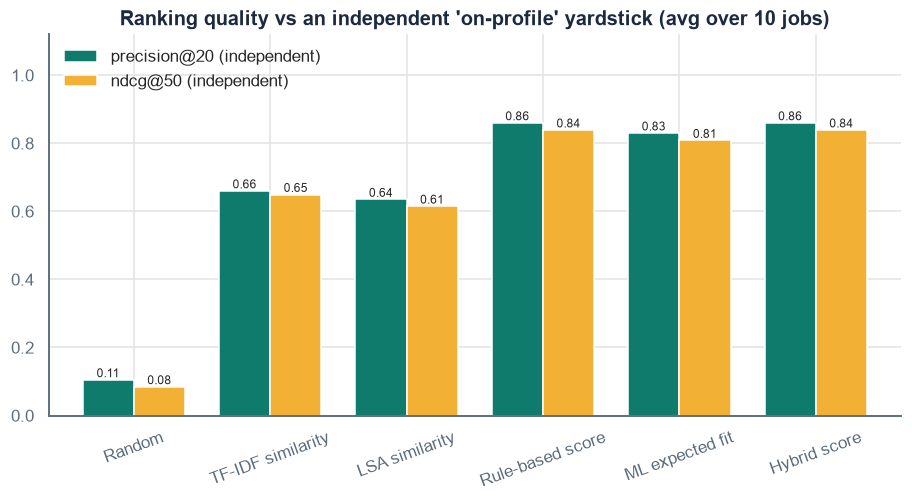

In [17]:
# Bar chart of the two independent ranking metrics for every method
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = rank_eval[["precision@20 (independent)", "ndcg@50 (independent)"]]
plot.plot.bar(ax=ax, color=[COLORS["teal"], COLORS["mustard"]], width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
ax.set_title("Ranking quality vs an independent 'on-profile' yardstick (avg over 10 jobs)")
ax.legend(frameon=False, loc="upper left")
save(fig, "04_ranking_comparison")
plt.show()

The independent yardstick (role in target list + experience in range) was **not** used to build any score, so it is a
fair test. Structured scoring (rule / ML / hybrid) puts far more on-profile candidates in the top 20 than text-only similarity.

### Choosing the hybrid weights
A first version used 0.60 rule + 0.25 ML + **0.15 text similarity**. Testing a few weightings on the independent
yardstick showed that **any** direct text-similarity weight pulls templated but off-profile resumes upward. Text similarity
is therefore not added directly — it stays an input to the ML model and is shown to recruiters as a separate
"semantic match" signal. Final weights: **0.70 rule + 0.30 ML**. *Note: weights were picked on the same yardstick that is reported, so the
final hybrid number is slightly optimistic; it should be re-checked on real recruiter decisions.*

In [18]:
# Try a few weight combinations (rule, ML, text) and measure on-profile precision of the top 20 / top 50
trials = []
for w_rule, w_ml, w_txt in [(0.60, 0.25, 0.15), (0.70, 0.20, 0.10), (0.65, 0.30, 0.05), (0.70, 0.30, 0.00), (1.0, 0.0, 0.0)]:
    s = w_rule * pairs["rule_score"] + w_ml * pairs["ml_expected_fit"] + w_txt * pairs["text_sim_scaled"]
    tmp = pairs.assign(s=s)
    trials.append({"rule": w_rule, "ml": w_ml, "text": w_txt,
                   "precision@20 (independent)": np.mean([g.nlargest(20, "s")["relevant_independent"].mean() for _, g in tmp.groupby("jd_id")]),
                   "precision@50 (independent)": np.mean([g.nlargest(50, "s")["relevant_independent"].mean() for _, g in tmp.groupby("jd_id")])})
weight_trials = pd.DataFrame(trials)
weight_trials.to_csv(OUTPUTS / "hybrid_weight_trials.csv", index=False)
weight_trials.round(3)

,rule,ml,text,precision@20 (independent),precision@50 (independent)
0,0.60,0.25,0.15,0.795,0.792
1,0.70,0.20,0.10,0.815,0.800
2,0.65,0.30,0.05,0.835,0.810
3,0.70,0.30,0.00,0.860,0.820
4,1.00,0.00,0.00,0.860,0.820


## 8. Robustness — are the rankings sensitive to the chosen weights?
The rule weights were chosen with business judgement. To check they are not "magic numbers", every weight is
randomly changed by up to ±30% (50 times) and the top-20 shortlist per job is compared with the original.

In [19]:
from scipy.stats import spearmanr

base_top = {j: set(g.nlargest(20, "rule_score")["candidate_id"]) for j, g in pairs.groupby("jd_id")}
overlaps, rhos = [], []
for _ in range(50):
    w = {k: v * rng.uniform(0.7, 1.3) for k, v in RULE_WEIGHTS.items()}
    total = sum(w.values())
    w = {k: v / total for k, v in w.items()}              # re-normalise so weights still add up to 1
    s = rule_score(pairs, w)
    for j, g in pairs.assign(s=s).groupby("jd_id"):
        overlaps.append(len(base_top[j] & set(g.nlargest(20, "s")["candidate_id"])) / 20)
        rhos.append(spearmanr(g["rule_score"], g["s"]).statistic)

print(f"Average top-20 overlap after weight changes : {np.mean(overlaps):.1%}  (min {np.min(overlaps):.0%})")
print(f"Average Spearman rank correlation (all cands): {np.mean(rhos):.3f}")

# keep the result for the report
pd.Series({"top20_overlap_mean": np.mean(overlaps), "top20_overlap_min": np.min(overlaps),
           "spearman_mean": np.mean(rhos)}).to_csv(OUTPUTS / "robustness_summary.csv", header=["value"])

Average top-20 overlap after weight changes : 93.2%  (min 60%)
Average Spearman rank correlation (all cands): 0.996


Shortlists stay largely the same even when weights move ±30%, so the ranking is **stable** and not driven by
one arbitrary weight. Where the top-20 changes, it is mostly reshuffling between candidates with near-identical scores.

## 9. Fairness check — institution tier

In [20]:
# Institution tier is NOT used in any score. Check that shortlist rates are similar across tiers.
fair = pairs.merge(cands[["candidate_id", "institution_tier"]], on="candidate_id")
rate = pd.crosstab(fair["institution_tier"], fair["recommendation"], normalize="index")[["Shortlist", "Review", "Reject"]]
from scipy.stats import chi2_contingency
chi2, p, _, _ = chi2_contingency(pd.crosstab(fair["institution_tier"], fair["recommendation"]))
print(f"Chi-square test tier vs recommendation: p = {p:.3f}  ->",
      "no significant difference" if p >= 0.05 else "significant difference - investigate")
rate.assign(chi2_p_value=p).to_csv(OUTPUTS / "fairness_by_tier.csv")
(rate * 100).round(2)

Chi-square test tier vs recommendation: p = 0.898  -> no significant difference


recommendation,Shortlist,Review,Reject
institution_tier,,,
Tier-1,7.73,8.97,83.30
Tier-2,7.94,8.80,83.26
Tier-3,7.96,8.95,83.09


## 10. Save the final models and scored pairs

In [21]:
import joblib

# final model trained on ALL pairs, used by the dashboard
final_model = clone(models[best_name]).fit(pairs[ENG_FEATURES], y)
joblib.dump({"model": final_model, "features": ENG_FEATURES, "name": best_name}, MODELS / "fit_classifier.pkl")

# explanation text for every pair
pairs["explanation"] = [explain(r, jds.loc[r["jd_id"]]) for _, r in pairs.iterrows()]

out = pairs.copy()
for c in ["mandatory_matched", "mandatory_missing", "optional_matched"]:
    out[c] = out[c].apply("|".join)
out.drop(columns=["random_score"]).to_csv(SCORED_FILE, index=False)
print("Saved", SCORED_FILE.name, out.shape, "and models/fit_classifier.pkl")

Saved scored_pairs.csv (50000, 55) and models/fit_classifier.pkl


## Limitations & next steps
- **Labels are rule-based**, not real hiring outcomes → collect recruiter shortlist / interview decisions for 2–3 months and re-train.
- **Templated resume text** limits what NLP can add; on real, richer resumes, sentence-embedding models (e.g. SBERT) should add more.
- **Job descriptions were written for this project**; real JDs should be parsed with the same skill dictionary.
- **Skill dictionary** has 30 skills; new skills need to be added as job families grow (the correction table makes this easy).